In [252]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [253]:
#We will merge the train and test_sets for data processing and for more flexibility when splitting

unsw_train_set = pd.read_csv('dataset/UNSW_NB15_training-set.csv')
unsw_test_set = pd.read_csv('dataset/UNSW_NB15_testing-set.csv')

unsw_set = pd.concat([unsw_train_set, unsw_test_set])

unsw_set.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [254]:
unsw_set.info()

<class 'pandas.core.frame.DataFrame'>
Index: 257673 entries, 0 to 82331
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 257673 non-null  int64  
 1   dur                257673 non-null  float64
 2   proto              257673 non-null  object 
 3   service            257673 non-null  object 
 4   state              257673 non-null  object 
 5   spkts              257673 non-null  int64  
 6   dpkts              257673 non-null  int64  
 7   sbytes             257673 non-null  int64  
 8   dbytes             257673 non-null  int64  
 9   rate               257673 non-null  float64
 10  sttl               257673 non-null  int64  
 11  dttl               257673 non-null  int64  
 12  sload              257673 non-null  float64
 13  dload              257673 non-null  float64
 14  sloss              257673 non-null  int64  
 15  dloss              257673 non-null  int64  
 16  sinpkt  

In [255]:
unsw_set.describe()

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,257673.000000,257673.000000,257673.000000,257673.000000,2.576730e+05,2.576730e+05,2.576730e+05,257673.000000,257673.000000,2.576730e+05,...,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000
mean,72811.823858,1.246715,19.777144,18.514703,8.572952e+03,1.438729e+04,9.125391e+04,180.000931,84.754957,7.060869e+07,...,5.238271,4.032677,8.322964,0.012819,0.012850,0.132005,6.800045,9.121049,0.014274,0.639077
std,48929.917641,5.974305,135.947152,111.985965,1.737739e+05,1.461993e+05,1.603446e+05,102.488268,112.762131,1.857313e+08,...,8.160822,5.831515,11.120754,0.116091,0.116421,0.681854,8.396266,10.874752,0.118618,0.480269
min,1.000000,0.000000,1.000000,0.000000,2.400000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,32210.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.078928e+01,62.000000,0.000000,1.231800e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,64419.000000,0.004285,4.000000,2.000000,5.280000e+02,1.780000e+02,2.955665e+03,254.000000,29.000000,7.439423e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,110923.000000,0.685777,12.000000,10.000000,1.362000e+03,1.064000e+03,1.250000e+05,254.000000,252.000000,8.000000e+07,...,4.000000,3.000000,8.000000,0.000000,0.000000,0.000000,8.000000,11.000000,0.000000,1.000000
max,175341.000000,59.999989,10646.000000,11018.000000,1.435577e+07,1.465753e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,59.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000


In [256]:
unsw_set.columns

Index(['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
       'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
       'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm',
       'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
      dtype='object')

In [257]:
features = pd.read_csv('dataset/UNSW-NB15_features.csv', encoding='cp1252')

features.head()

,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol


In [258]:
#It creates a dictionary which explains each feauture name because they are quite vague
feature_explanations = dict(zip(features['Name'], features['Description']))

feature_explanations

{'srcip': 'Source IP address',
 'sport': 'Source port number',
 'dstip': 'Destination IP address',
 'dsport': 'Destination port number',
 'proto': 'Transaction protocol',
 'state': 'Indicates to the state and its dependent protocol, e.g. ACC, CLO, CON, ECO, ECR, FIN, INT, MAS, PAR, REQ, RST, TST, TXD, URH, URN, and (-) (if not used state)',
 'dur': 'Record total duration',
 'sbytes': 'Source to destination transaction bytes ',
 'dbytes': 'Destination to source transaction bytes',
 'sttl': 'Source to destination time to live value ',
 'dttl': 'Destination to source time to live value',
 'sloss': 'Source packets retransmitted or dropped ',
 'dloss': 'Destination packets retransmitted or dropped',
 'service': 'http, ftp, smtp, ssh, dns, ftp-data ,irc  and (-) if not much used service',
 'Sload': 'Source bits per second',
 'Dload': 'Destination bits per second',
 'Spkts': 'Source to destination packet count ',
 'Dpkts': 'Destination to source packet count',
 'swin': 'Source TCP window adve

In [259]:
#One-hot encode the categorical features

#Separate data
categorical_columns = unsw_set.select_dtypes(include = 'object').columns

#Set up One-hot encoder
encoder = OneHotEncoder(sparse_output=False)

#Encode categorical features
encoded_data = encoder.fit_transform(unsw_set[categorical_columns])

#Create dataFrame with encoded categorical features
encoded_data_frame = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(categorical_columns))




In [260]:
#Scale the numerical data

#Select numerical columns which are not fit for scaling
not_scalable_columns = ['id', 'is_sm_ips_ports', 'is_ftp_login', 'label']


numerical_data = unsw_set.drop(columns=list(categorical_columns)+not_scalable_columns)

scaler = StandardScaler()

numerical_data_scaled = scaler.fit_transform(numerical_data)

numerical_data_frame = pd.DataFrame(numerical_data_scaled, columns=numerical_data.columns)





In [261]:
#Concatenate the encoded categorical feautures with the scaled numerical features and the unscalable features to create the final dataFrame

#Reset indexes on all in order for the concatenation to work
numerical_data_frame = numerical_data_frame.reset_index(drop=True)
encoded_data_frame = encoded_data_frame.reset_index(drop=True)
not_scalable_data_frame = unsw_set[not_scalable_columns].reset_index(drop=True)

final_set = pd.concat([not_scalable_data_frame,numerical_data_frame, encoded_data_frame], axis=1)

final_set.head()



,id,is_sm_ips_ports,is_ftp_login,label,dur,spkts,dpkts,sbytes,dbytes,rate,...,attack_cat_Analysis,attack_cat_Backdoor,attack_cat_DoS,attack_cat_Exploits,attack_cat_Fuzzers,attack_cat_Generic,attack_cat_Normal,attack_cat_Reconnaissance,attack_cat_Shellcode,attack_cat_Worms
0,1,0,0,0,-0.188346,-0.101342,-0.129612,-0.047849,-0.097232,-0.568650,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,2,0,0,0,-0.099897,-0.042496,0.173998,-0.045110,0.188966,-0.568623,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,3,0,0,0,0.063006,-0.086630,-0.022456,-0.047239,-0.008217,-0.569024,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,4,0,1,0,0.072800,-0.057207,-0.058174,-0.045720,-0.093142,-0.569027,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,5,0,0,0,-0.133449,-0.071919,-0.111753,-0.046261,-0.096576,-0.568904,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [262]:
#Split the data into train, validation and test samples

x_train, x_test, y_train, y_test = train_test_split(final_set.drop(columns='label'), final_set['label'], test_size=0.2)


x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.25)

#After that we have 20% as the testing set, 20% as the validation set and 60% as the training set

([<matplotlib.axis.XTick at 0x2402e10fed0>,
 [Text(0, 0, '0'), Text(1, 0, '1')])

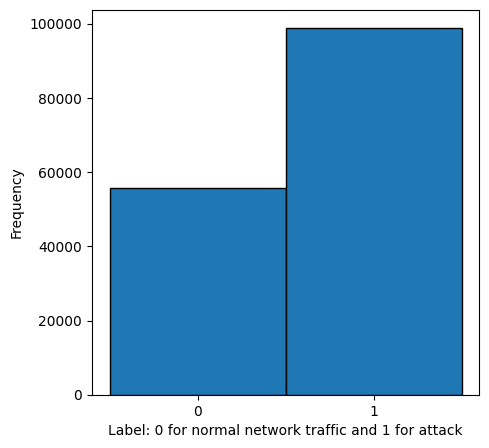

In [272]:
fig = plt.figure(figsize=(5,5))
plt.hist(x = y_train, bins = [-0.5, 0.5, 1.5], edgecolor = 'black')
plt.xlabel("Label: 0 for normal network traffic and 1 for attack")
plt.ylabel("Frequency")
plt.xticks([0,1])

In [263]:
#Select the most informative features from Orange and make a scatter matrix

informative_features = ['sttl', 'dttl', 'ct_state_ttl']


#Explain the features
for feature in informative_features:
    print(feature_explanations[feature])



Source to destination time to live value 
Destination to source time to live value
No. for each state (6) according to specific range of values for source/destination time to live (10) (11).


array([[<Axes: xlabel='sttl', ylabel='sttl'>,
        <Axes: xlabel='dttl', ylabel='sttl'>,
        <Axes: xlabel='ct_state_ttl', ylabel='sttl'>],
       [<Axes: xlabel='sttl', ylabel='dttl'>,
        <Axes: xlabel='dttl', ylabel='dttl'>,
        <Axes: xlabel='ct_state_ttl', ylabel='dttl'>],
       [<Axes: xlabel='sttl', ylabel='ct_state_ttl'>,
        <Axes: xlabel='dttl', ylabel='ct_state_ttl'>,
        <Axes: xlabel='ct_state_ttl', ylabel='ct_state_ttl'>]],
      dtype=object)

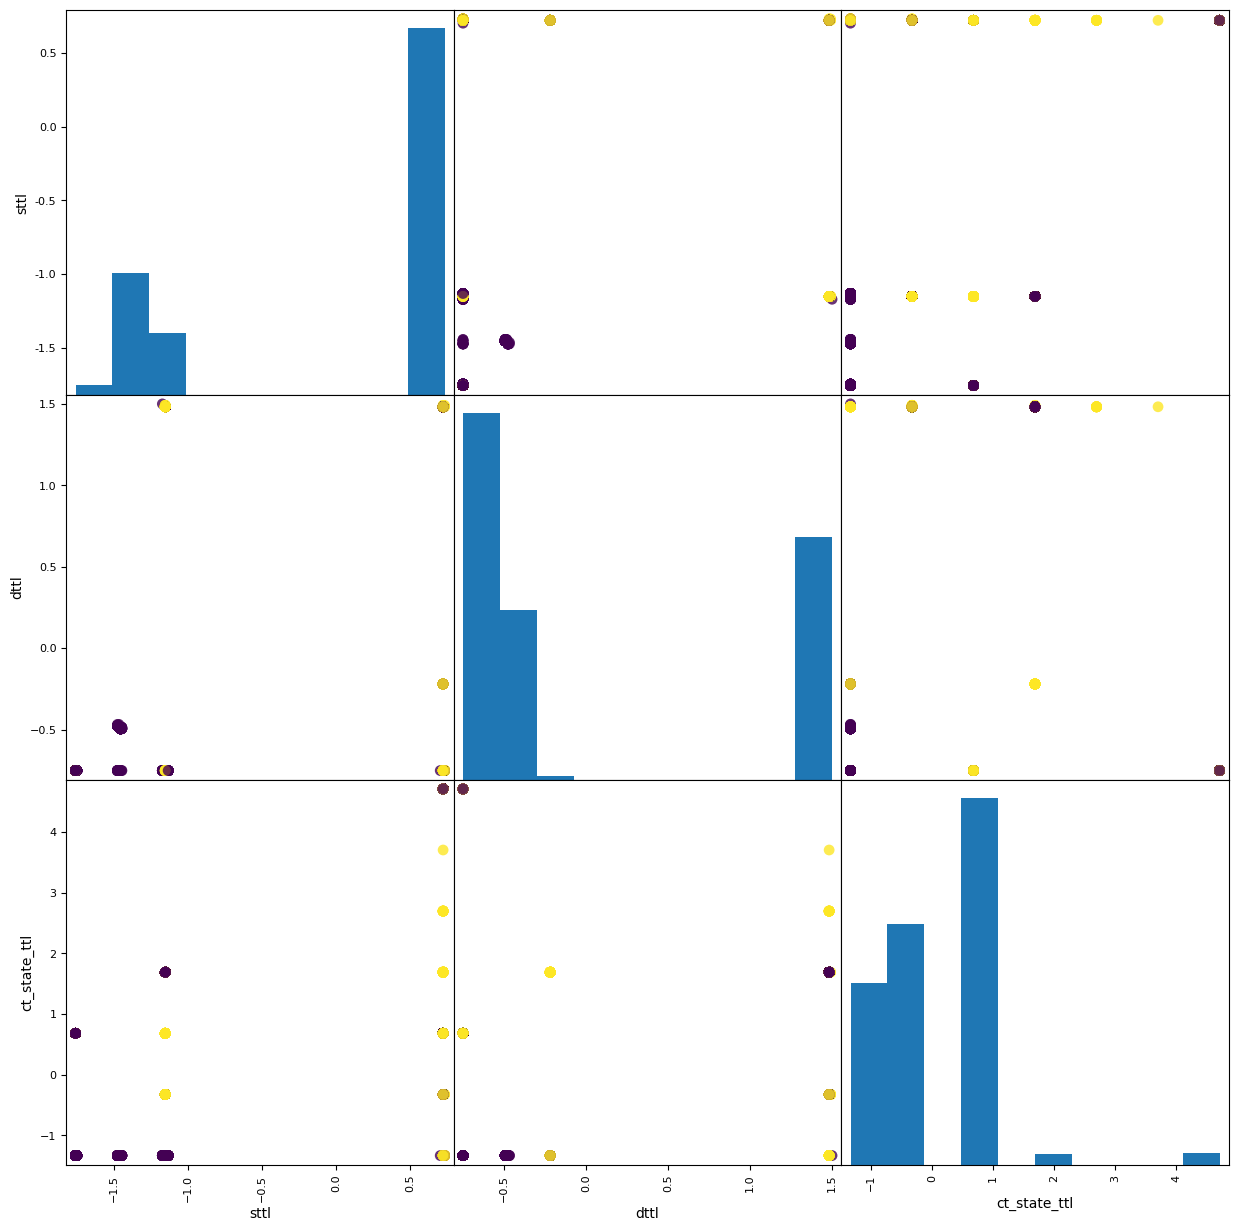

In [264]:
pd.plotting.scatter_matrix(x_train[informative_features], 
                           c=y_train, 
                           figsize=(15,15),
                           marker='0',
                           s=60,
                           alpha=0.8)